# BlackJackAI: Statistical Analysis

Can a Deep Q-Network learn blackjack wager sizing decisions that outperform classical betting policies and a calibrated model based expected log betting strategy? This notebook looks at the results, rather than the training process.

Seven strategies were tested over 300 sessions each, with 500 betting opportunities per session. They all use the same 'BasicStrategy' to play their hands. The difference is how much they choose to bet, or whether they bet at all.

I'll compare their returns, the risks they took and how often they placed bets. I'll then test the main question: did the selected DQN outperform the model based log strategy? The second DQN is included as an exploratory comparison.

Everything below uses the saved simulation results. No new games are played and no models are trained.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Find the project folder whether this notebook opens from the root or notebooks.
root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from research.analysis import (
    STRATEGIES,
    SESSION_FIELDS,
    _read_csv,
    validate_sessions,
    validate_summary,
    bootstrap_indices,
    strategy_statistics,
    paired_comparison,
)

metadata = json.loads((root / "results/experiment_metadata.json").read_text())
groups = validate_sessions(_read_csv(root / "results/sessions.csv", SESSION_FIELDS), metadata)
validate_summary(_read_csv(root / "results/summary.csv"), groups)

# Use the same 2,000 bootstrap samples for every strategy.
indices = bootstrap_indices(len(groups["dqn"]))
stats = {name: strategy_statistics(groups[name], indices) for name in STRATEGIES}

labels = {
    "flat": "Flat",
    "hi_lo": "Hi Lo",
    "calibrated_kelly": "Calibrated Kelly",
    "model_based_log": "Model based log",
    "dqn": "Selected DQN",
    "dqn_runner_up": "Exploratory DQN",
    "never_bet": "Never bet",
}
names = [labels[name] for name in STRATEGIES]

print(f"Loaded {sum(len(rows) for rows in groups.values()):,} sessions.")
print(f"Each strategy has {len(groups['dqn'])} sessions of 500 betting opportunities.")


Loaded 2,100 sessions.
Each strategy has 300 sessions of 500 betting opportunities.


## 1. Comparing returns

We start with log growth, which measures how much the bankroll changed during a session relative to where it started.

$$G = \log\left(\frac{B_T}{B_0}\right)$$

Every strategy starts with 1,000 simulated units. A positive value means the bankroll grew and a negative value means it shrank.

The table shows the average final bankroll and average log growth for each strategy. The confidence intervals are calculated by resampling complete sessions, not individual bets.


In [2]:
header = "| Strategy | Average final bankroll | Mean log growth | 95% confidence interval |"
rows = [header, "|---|---:|---:|---:|"]

for name in STRATEGIES:
    results = stats[name]
    growth = results["mean_log_growth"]
    lower, upper = growth["ci95"]
    rows.append(
        f"| {labels[name]} | {results['mean_terminal_bankroll']['estimate']:,.2f} | "
        f"{growth['estimate']:+.5f} | [{lower:+.5f}, {upper:+.5f}] |"
    )

display(Markdown("\n".join(rows)))


| Strategy | Average final bankroll | Mean log growth | 95% confidence interval |
|---|---:|---:|---:|
| Flat | 998.79 | -0.00153 | [-0.00444, +0.00137] |
| Hi Lo | 1,008.64 | +0.00685 | [-0.00005, +0.01350] |
| Calibrated Kelly | 998.75 | -0.00162 | [-0.00461, +0.00137] |
| Model based log | 998.40 | -0.00227 | [-0.00627, +0.00173] |
| Selected DQN | 990.99 | -0.01971 | [-0.03724, -0.00349] |
| Exploratory DQN | 994.03 | -0.01419 | [-0.02924, -0.00008] |
| Never bet | 1,000.00 | +0.00000 | [+0.00000, +0.00000] |

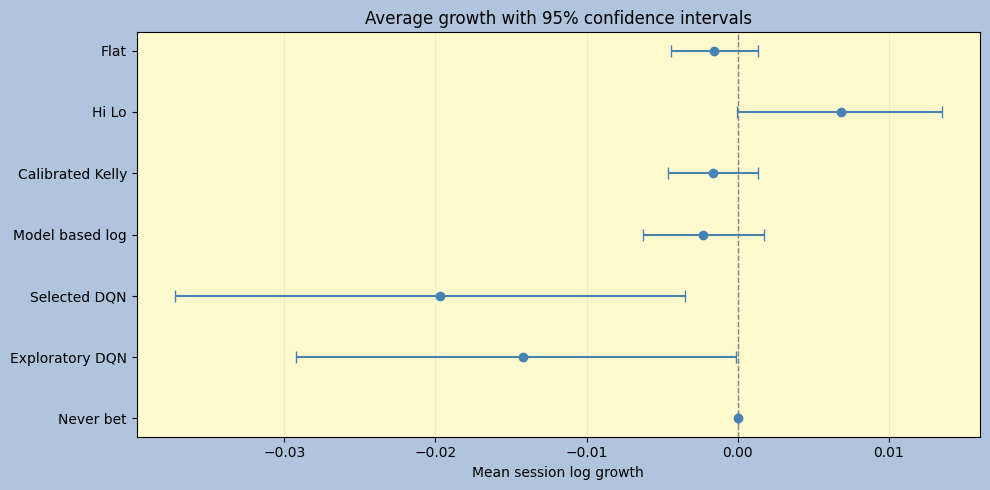

In [3]:
means = [stats[name]["mean_log_growth"]["estimate"] for name in STRATEGIES]
intervals = [stats[name]["mean_log_growth"]["ci95"] for name in STRATEGIES]
errors = [
    [mean - interval[0] for mean, interval in zip(means, intervals)],
    [interval[1] - mean for mean, interval in zip(means, intervals)],
]

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor("lightsteelblue")
ax.set_facecolor("lemonchiffon")

ax.errorbar(means, range(len(names)), xerr=errors, fmt="o", color="steelblue", capsize=4)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Mean session log growth")
ax.set_title("Average growth with 95% confidence intervals")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


Hi Lo had the highest average log growth at about **0.00685**. The selected DQN was at the other end, with an average of **−0.01971**.

That is what happened in these simulations. It does not mean Hi Lo will always be the best strategy. The intervals also describe uncertainty around each strategy's average, rather than directly testing the difference between two strategies. I'll do that comparison later.


## 2. Bankroll and drawdowns

Looking at averages is useful, but it doesn't tell the whole story. Two strategies can have similar average returns while exposing the player to very different losses.

The first graph shows the distribution of bankrolls at the end of each session. The second shows maximum drawdown, which is the biggest percentage fall from a previous bankroll peak during that session.


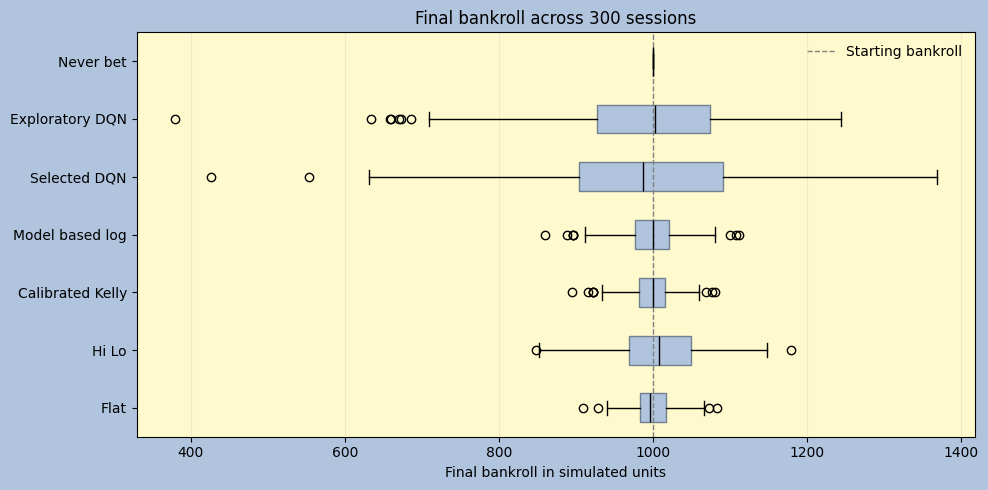

In [4]:
bankrolls = [[row["final_bankroll"] for row in groups[name]] for name in STRATEGIES]

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor("lightsteelblue")
ax.set_facecolor("lemonchiffon")

ax.boxplot(
    bankrolls,
    tick_labels=names,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "lightsteelblue", "edgecolor": "slategray"},
    medianprops={"color": "black"},
)
ax.axvline(1000, color="gray", linestyle="--", linewidth=1, label="Starting bankroll")
ax.set_xlabel("Final bankroll in simulated units")
ax.set_title("Final bankroll across 300 sessions")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


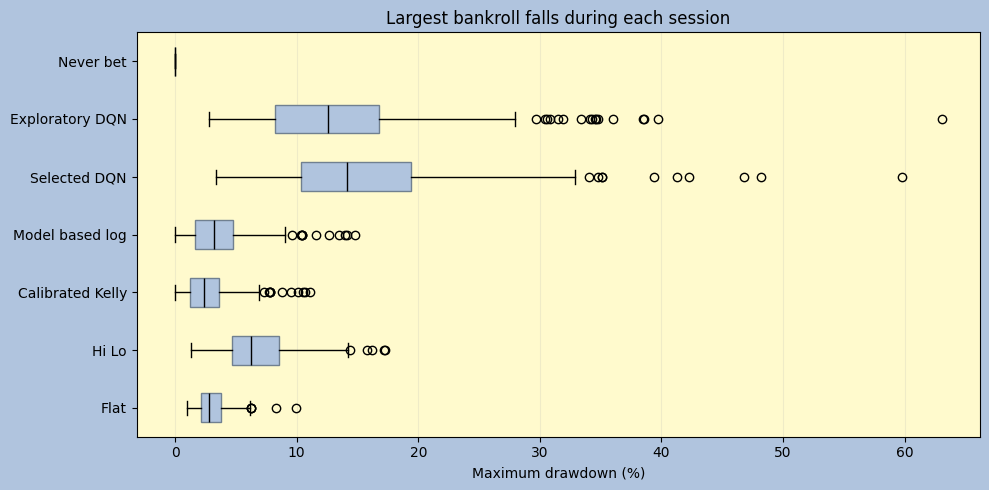

In [5]:
drawdowns = [[100 * row["max_drawdown"] for row in groups[name]] for name in STRATEGIES]

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor("lightsteelblue")
ax.set_facecolor("lemonchiffon")

ax.boxplot(
    drawdowns,
    tick_labels=names,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "lightsteelblue", "edgecolor": "slategray"},
    medianprops={"color": "black"},
)
ax.set_xlabel("Maximum drawdown (%)")
ax.set_title("Largest bankroll falls during each session")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


The selected DQN took noticeably more risk. Its average maximum drawdown was about 16.0%, compared with 3.6% for model based log betting. Its final bankrolls also varied more widely.

Never bet stays at 1,000 units because it never risks anything. It's a useful reference, but it isn't trying to make money.

There were no cases of ruin in the 300 sessions for any strategy. That is reassuring for this particular simulation, but it doesn't mean ruin is impossible.


## 3. How often did the strategies bet?

We should also look at how the strategies behaved, not just how much money they made.

Participation rate tells us how often a strategy placed a bet. Average bet size tells us how much it wagered when it did decide to play. Keeping these separate matters because a strategy might bet rarely but place larger wagers when it sees an opportunity.


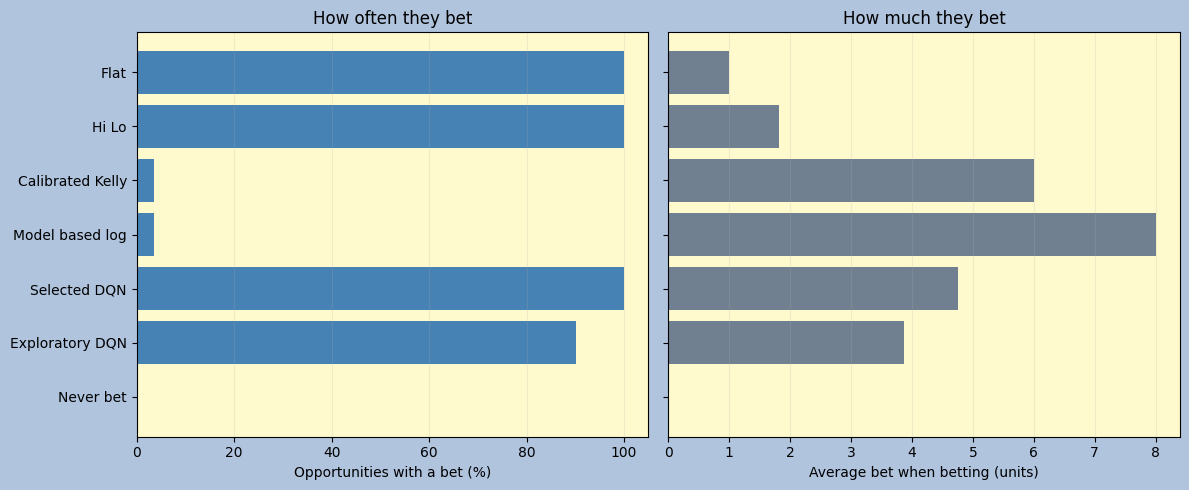

In [6]:
rates = [100 * stats[name]["participation_rate"]["estimate"] for name in STRATEGIES]
wagers = [stats[name]["mean_wager_conditional_on_bet"]["estimate"] or 0 for name in STRATEGIES]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
fig.patch.set_facecolor("lightsteelblue")

for ax in axes:
    ax.set_facecolor("lemonchiffon")
    ax.grid(axis="x", alpha=0.2)

axes[0].barh(range(len(names)), rates, color="steelblue")
axes[0].set_yticks(range(len(names)), names)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 105)
axes[0].set_xlabel("Opportunities with a bet (%)")
axes[0].set_title("How often they bet")

axes[1].barh(range(len(names)), wagers, color="slategray")
axes[1].set_xlabel("Average bet when betting (units)")
axes[1].set_title("How much they bet")

plt.tight_layout()
plt.show()


The selected DQN bet on about **99.93%** of opportunities, with an average wager of **4.76 units** when it did bet. In comparison, the calibrated strategies only bet on about **3.45%** of opportunities, although their wagers were larger when they chose to participate.

This gives us a possible explanation for the DQN's worse returns and larger drawdowns. It exposed itself to the game far more often. However, these results alone cannot tell us whether that was the main cause of its poor performance.


## 4. Did the DQN beat the model based strategy?

This is the main statistical question. we compare the selected DQN with the model based log strategy using the difference in their session log growth.

$$d_i = G_{\mathrm{DQN},i} - G_{\mathrm{Model},i}$$

Because both strategies were evaluated using the same 300 random seeds, we can compare results in matched pairs. We then use 2,000 bootstrap resamples of the 300 session pairs to estimate a 95% confidence interval for the mean difference.

A positive result would favour the DQN. A negative result would favour the model based strategy. Using the same seeds helps make the comparison fairer, although it does not guarantee identical cards in every session.


Mean difference: -0.017445
95% confidence interval: [-0.035090, -0.001426]


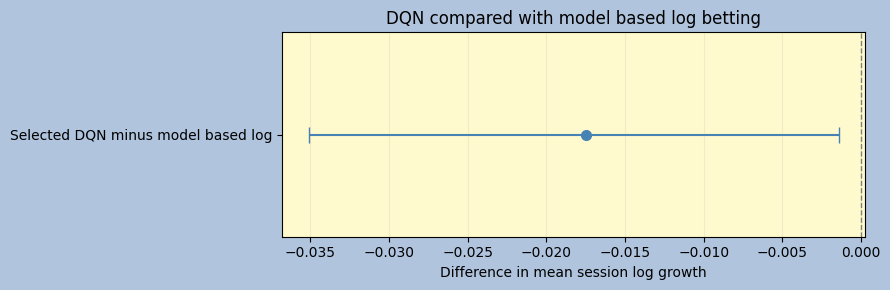

In [7]:
dqn_growth = [row["log_growth"] for row in groups["dqn"]]
model_growth = [row["log_growth"] for row in groups["model_based_log"]]

comparison = paired_comparison(dqn_growth, model_growth, indices)
difference = comparison["estimate"]
lower, upper = comparison["ci95"]

print(f"Mean difference: {difference:+.6f}")
print(f"95% confidence interval: [{lower:+.6f}, {upper:+.6f}]")

fig, ax = plt.subplots(figsize=(9, 3))
fig.patch.set_facecolor("lightsteelblue")
ax.set_facecolor("lemonchiffon")

ax.errorbar(
    difference,
    0,
    xerr=[[difference - lower], [upper - difference]],
    fmt="o",
    color="steelblue",
    capsize=6,
    markersize=7,
)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks([0], ["Selected DQN minus model based log"])
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel("Difference in mean session log growth")
ax.set_title("DQN compared with model based log betting")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


The average difference was **−0.017445**, with a 95% confidence interval from **−0.035090 to −0.001426**.

The entire interval is below zero. That gives us evidence that the selected DQN had lower average log growth than the model based strategy in this experiment.

This is a result about these particular models and simulation settings. It doesn't mean every DQN will lose to a traditional strategy, or that the model based strategy is guaranteed to make money.


## 5. What to take from the results

The selected DQN did not beat the model based log strategy. It finished with worse average log growth, and its drawdowns were substantially higher. The fact that it placed bets almost every time is particularly interesting, especially compared with the calibrated strategies that waited for a smaller number of opportunities.

That doesn't tell us exactly why the DQN behaved this way. We would need more detailed information about the game state and its decisions to investigate that properly. The second DQN is also only an exploratory comparison, so we shouldn't treat it as a second independent test of the main hypothesis.

For this project, the conclusion is simple. **Training a reinforcement learning model did not produce a better betting policy than the simpler calibrated benchmark.** That's still a useful finding. It shows why testing a model against sensible baselines matters, rather than assuming a more complicated method will perform better.
